In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("fakenews.csv")

In [2]:
# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Display dataset information
print("Dataset loaded successfully!")
print("Total articles:", len(df))

print("\nNews categories:")
print(df["label"].value_counts())

print("\nSample data:")
print(df[["label", "text"]].head())

Dataset loaded successfully!
Total articles: 2212

News categories:
label
Fake    1110
Real    1102
Name: count, dtype: int64

Sample data:
  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...


In [3]:
# Hyperbolic and exaggerated words
hyperbolic_words = [
    "unbelievable", "incredible", "shocking", "amazing",
    "outrageous", "massive", "huge", "worst",
    "best", "disaster", "catastrophic", "miracle"
]

# Potentially misleading or attention-grabbing phrases
misleading_phrases = [
    "you won't believe",
    "what they don't want you to know",
    "secret revealed",
    "the truth about",
    "shocking truth",
    "hidden truth",
    "proof that",
    "everyone is talking about"
]

# Dramatic expressions
dramatic_phrases = [
    "breaking news",
    "shocking revelation",
    "exposed",
    "bombshell",
    "shocking discovery",
    "huge scandal",
    "jaw-dropping",
    "unprecedented crisis"
]

print("Sensational language categories created!")

print("Hyperbolic words:", len(hyperbolic_words))
print("Potentially misleading phrases:", len(misleading_phrases))
print("Dramatic expressions:", len(dramatic_phrases))

Sensational language categories created!
Hyperbolic words: 12
Potentially misleading phrases: 8
Dramatic expressions: 8


In [4]:
# Function to detect sensational language
def detect_sensationalism(text):
    text = str(text).lower()

    hyperbolic_count = sum(
        len(re.findall(r"\b" + re.escape(word) + r"\b", text))
        for word in hyperbolic_words
    )

    misleading_count = sum(
        text.count(phrase) for phrase in misleading_phrases
    )

    dramatic_count = sum(
        text.count(phrase) for phrase in dramatic_phrases
    )

    return pd.Series({
        "hyperbolic_count": hyperbolic_count,
        "misleading_count": misleading_count,
        "dramatic_count": dramatic_count
    })


# Apply detection to each article
sensational_results = df["text"].apply(detect_sensationalism)

# Combine results with the original dataset
sensational_df = pd.concat(
    [df[["news_id", "label"]].reset_index(drop=True),
     sensational_results.reset_index(drop=True)],
    axis=1
)

# Calculate total sensational indicators
sensational_df["total_indicators"] = (
    sensational_df["hyperbolic_count"]
    + sensational_df["misleading_count"]
    + sensational_df["dramatic_count"]
)

# Display results
print(sensational_df.head())

   news_id label  hyperbolic_count  misleading_count  dramatic_count  \
0        1  Real                 0                 0               0   
1        2  Real                 0                 0               0   
2        3  Fake                 0                 0               0   
3        4  Fake                 0                 0               0   
4        5  Real                 0                 0               0   

   total_indicators  
0                 0  
1                 0  
2                 0  
3                 0  
4                 0  


In [5]:
# Compare average sensational language indicators
sensational_comparison = (
    sensational_df.groupby("label")[
        [
            "hyperbolic_count",
            "misleading_count",
            "dramatic_count",
            "total_indicators"
        ]
    ]
    .mean()
    .round(2)
)

# Display comparison
print("Sensationalism Comparison: Real vs Fake News\n")
print(sensational_comparison)

Sensationalism Comparison: Real vs Fake News

       hyperbolic_count  misleading_count  dramatic_count  total_indicators
label                                                                      
Fake                0.0               0.0             0.0               0.0
Real                0.0               0.0             0.0               0.0


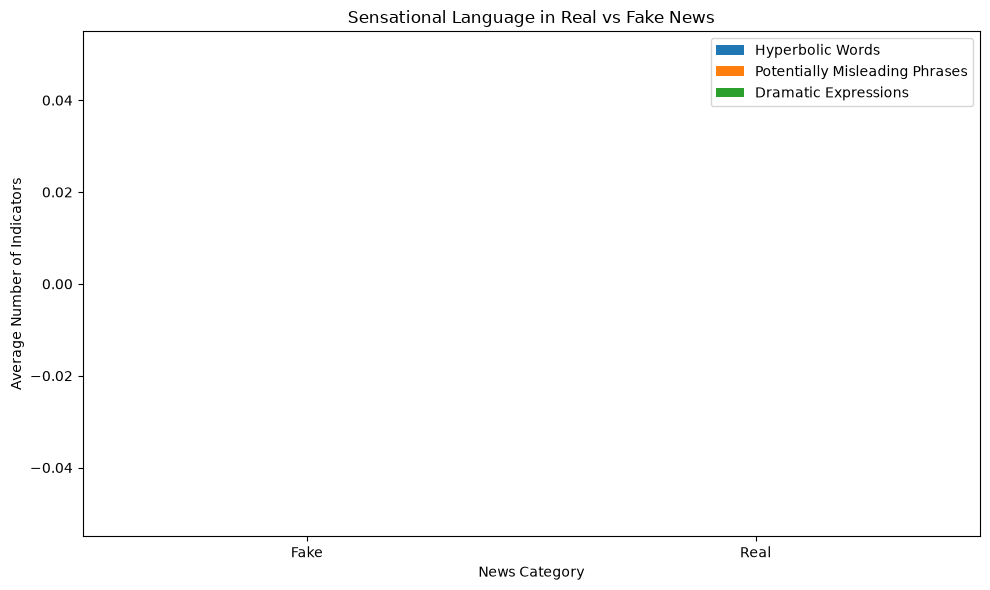

In [6]:
# Plot sensational language indicators
sensational_comparison[
    ["hyperbolic_count", "misleading_count", "dramatic_count"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sensational Language in Real vs Fake News")
plt.xlabel("News Category")
plt.ylabel("Average Number of Indicators")
plt.xticks(rotation=0)
plt.legend([
    "Hyperbolic Words",
    "Potentially Misleading Phrases",
    "Dramatic Expressions"
])
plt.tight_layout()
plt.show()

In [7]:
# Save article-level sensationalism analysis
sensational_df.to_csv("T23_sensationalism_analysis.csv", index=False)

# Save Real vs Fake comparison
sensational_comparison.to_csv(
    "T23_sensationalism_comparison.csv"
)

# Display comparison
print("Sensationalism Comparison:\n")
print(sensational_comparison)

# Identify the category with more sensational indicators
if "Fake" in sensational_comparison.index and "Real" in sensational_comparison.index:
    fake_count = sensational_comparison.loc["Fake", "total_indicators"]
    real_count = sensational_comparison.loc["Real", "total_indicators"]

    if fake_count > real_count:
        print("\nFake news has a higher average number of sensational indicators.")
    elif real_count > fake_count:
        print("\nReal news has a higher average number of sensational indicators.")
    else:
        print("\nBoth categories have the same average number of sensational indicators.")

print("\nSensationalism analysis completed successfully!")

Sensationalism Comparison:

       hyperbolic_count  misleading_count  dramatic_count  total_indicators
label                                                                      
Fake                0.0               0.0             0.0               0.0
Real                0.0               0.0             0.0               0.0

Both categories have the same average number of sensational indicators.

Sensationalism analysis completed successfully!
